# Writing supermarket data to and reading data from a database

**This Jupyter notebook does the following:**

- Creates a SQLite database and a SQL table for supermarket data
- Reads the prepared supermarket data from a CSV file and writes it into the SQL table
- Queries and summarizes the data using SQL
- Plots the number of supermarkets by brand
- Closes the database connection

## Libraries and settings

In [1]:
import fnmatch
import os
import sqlite3

import matplotlib.pyplot as plt
import pandas as pd

print(os.getcwd())

/workspaces/applied_research_methods/Week_08


## Create the SQLite database

In [2]:
conn = sqlite3.connect('./Data/supermarkets_database.db')
cursor = conn.cursor()

db_files = fnmatch.filter(os.listdir('./Data'), '*.db')
print('\n'.join(db_files))

supermarkets_database.db
apartment_database.db


## Create the SQL table

In [3]:
# Drop the table first so the notebook can be run again without duplicating rows
cursor.execute('DROP TABLE IF EXISTS supermarkets_table')

cursor.execute('''CREATE TABLE supermarkets_table (
    object_type TEXT,
    osm_id INTEGER,
    latitude REAL,
    longitude REAL,
    brand TEXT,
    shop_type TEXT,
    city TEXT,
    street TEXT,
    housenumber TEXT,
    postcode INTEGER
)''')
conn.commit()

## Read the CSV file into a data frame

In [4]:
df = pd.read_csv('./Data/supermarkets_data_prepared.csv',
                 encoding='utf-8')

print('Data shape:', df.shape)
df.head()

Data shape: (3392, 10)


,type,id,lat,lon,brand,shop,city,street,housenumber,postcode
0,node,33126515,47.155616,9.037915,Spar,supermarket,NaN,NaN,NaN,NaN
1,node,36726161,47.226191,8.980329,Migros,supermarket,Uznach,Zürcherstrasse,25,8730.0
2,node,39768209,47.225069,8.969981,Coop,supermarket,Uznach,NaN,NaN,8730.0
3,node,39947904,47.376732,8.542161,Coop,supermarket,Zürich,Bahnhofbrücke,1,8001.0
4,node,48932835,47.375020,8.522895,Migros,supermarket,Zürich,Wengistrasse,7,8004.0


## Write the data to the SQL table

In [5]:
df_sql = df.rename(columns={
    'type': 'object_type',
    'id': 'osm_id',
    'lat': 'latitude',
    'lon': 'longitude',
    'shop': 'shop_type'
})

df_sql.to_sql(name='supermarkets_table',
              con=conn,
              index=False,
              if_exists='append')
conn.commit()

print(f"Rows written to database: {len(df_sql)}")

Rows written to database: 3392


## Query the SQL table

In [6]:
df_supermarkets = pd.read_sql_query('''
    SELECT osm_id, brand, shop_type, city, latitude, longitude
    FROM supermarkets_table
    ORDER BY brand, city
    LIMIT 10
''', conn)

display(df_supermarkets)

,osm_id,brand,shop_type,city,latitude,longitude
0,60271452,None,supermarket,None,47.406671,9.305450
1,70656485,None,supermarket,None,47.491253,8.733981
2,95582038,None,supermarket,None,47.050385,9.059214
3,112148390,None,supermarket,None,47.448772,8.215075
4,128269749,None,supermarket,None,47.381684,8.238918
5,243155992,None,supermarket,None,47.526222,7.696823
6,250216543,None,supermarket,None,46.181393,7.294360
7,251364445,None,supermarket,None,47.566732,9.097048
8,251539566,None,supermarket,None,47.446280,8.403869
9,259794007,None,supermarket,None,47.245172,8.608109


## Count supermarkets by brand

In [7]:
df_brand_counts = pd.read_sql_query('''
    SELECT brand, COUNT(*) AS supermarket_count
    FROM supermarkets_table
    WHERE brand IS NOT NULL AND TRIM(brand) <> ''
    GROUP BY brand
    ORDER BY supermarket_count DESC, brand
''', conn)

display(df_brand_counts)

,brand,supermarket_count
0,Coop,588
1,Migros,532
2,Denner,494
3,Volg,264
4,ALDI,96
5,Lidl,77
6,Spar,76
7,Landi,61
8,Aldi,38
9,VOI Migros Partner,33


## Plot the number of supermarkets by brand

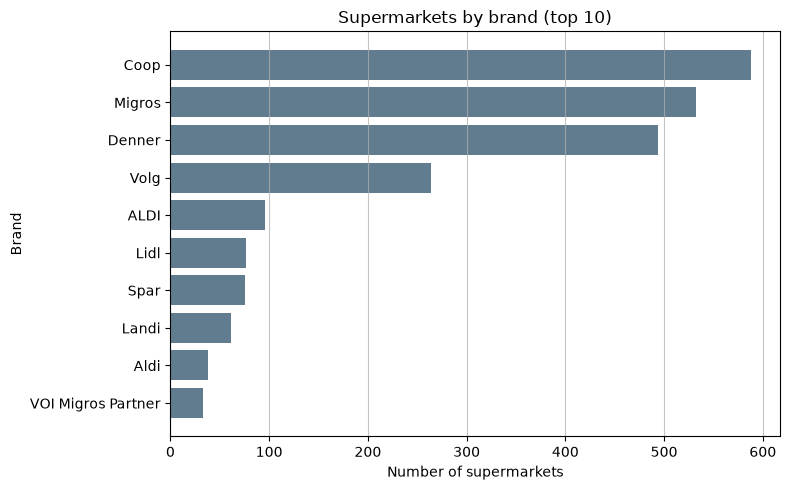

In [8]:
top_brands = df_brand_counts.head(10).sort_values('supermarket_count')

plt.figure(figsize=(8, 5))
plt.barh(top_brands['brand'], top_brands['supermarket_count'], color='#607c8e')
plt.title('Supermarkets by brand (top 10)')
plt.xlabel('Number of supermarkets')
plt.ylabel('Brand')
plt.grid(axis='x', alpha=0.75)
plt.tight_layout()
plt.show()

## Additional SQL query: supermarkets by city

In [9]:
df_city_counts = pd.read_sql_query('''
    SELECT city, COUNT(*) AS supermarket_count
    FROM supermarkets_table
    WHERE city IS NOT NULL AND TRIM(city) <> ''
    GROUP BY city
    ORDER BY supermarket_count DESC, city
    LIMIT 10
''', conn)

display(df_city_counts)

,city,supermarket_count
0,Zürich,156
1,Basel,55
2,Bern,33
3,Luzern,30
4,Genève,28
5,Winterthur,27
6,Biel/Bienne,16
7,Uster,13
8,Emmenbrücke,10
9,Lausanne,10


## Filter supermarkets in Winterthur

In [ ]:
df_winterthur = pd.read_sql_query('''
    SELECT *
    FROM supermarkets_table
    WHERE city = ?
''', conn, params=('Winterthur',))

print(f"Supermarkets in Winterthur: {len(df_winterthur)}")
display(df_winterthur)

## Close the database connection

In [10]:
conn.close()
print('Database connection closed.')

Database connection closed.
